# Avance 1 — Pronóstico mensual de órdenes entrantes

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Grupo:** _(número)_

**Integrantes:** _(nombres completos)_

Este notebook reproduce el análisis exploratorio y el primer modelo (SARIMA estacional con período 12) del avance, con el ingenuo estacional y AutoETS como referencias. Se ejecuta de principio a fin en un entorno limpio de Colab (Python 3). Los datos están incluidos en la celda 3, así que no depende de ningún enlace externo.

Contenido:
1. Configuración, versiones y semilla
2. Datos y su origen
3. Análisis exploratorio (estadísticas y tres figuras)
4. Primer modelo: identificación del SARIMA
5. Validación de ventana expansiva contra los modelos de referencia
6. Diagnóstico de residuos y pronóstico a 3 meses

## 1. Configuración, versiones y semilla

In [1]:
%pip install -q statsforecast

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: C:\Users\Light Force CR\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [2]:
import io, os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import statsmodels, statsforecast, scipy
from scipy.stats import wilcoxon
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoETS, AutoARIMA

warnings.filterwarnings("ignore")
SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__)
print("statsmodels", statsmodels.__version__, "| statsforecast", statsforecast.__version__)

# Estilo de las figuras: paleta categórica validada (azul, naranja, aqua), rejilla tenue, sin bordes superior/derecho
C = dict(azul="#2a78d6", naranja="#eb6834", aqua="#1baf7a", tinta="#0b0b0b", tinta2="#52514e",
         tenue="#898781", rejilla="#e1e0d9", base="#c3c2b7", fondo="#fcfcfb",
         azul_claro="#86b6ef", azul_medio="#3987e5", azul_oscuro="#1c5cab")
plt.rcParams.update({
    "figure.facecolor": C["fondo"], "axes.facecolor": C["fondo"], "axes.edgecolor": C["base"],
    "axes.labelcolor": C["tinta2"], "xtick.color": C["tenue"], "ytick.color": C["tenue"],
    "text.color": C["tinta"], "axes.grid": True, "grid.color": C["rejilla"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.dpi": 110, "legend.frameon": False})
os.makedirs("figuras", exist_ok=True)

nombres_mes = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FMT_MES = FuncFormatter(lambda x, pos: "%s-%s" % (nombres_mes[mdates.num2date(x).month - 1], mdates.num2date(x).strftime("%y")))   # ej. ene-26

pandas 2.2.3 | numpy 2.4.6 | scipy 1.17.1
statsmodels 0.14.6 | statsforecast 2.1.1


## 2. Datos y su origen

**Fuente:** base de datos analítica de LightForce Orthodontics (Databricks), tabla `analytics.manufacturing.mfg_all_orders`, consultada el 26 de octubre de 2026 con autorización de la empresa. Cada fila de la tabla es un caso de manufactura (un _epic_ de Jira).

**Definición de orden entrante:** caso nuevo (`order_type = 'New case'`) con fecha de recepción del scan (`scan_received_date`). Los _Reorder_ no tienen scan, porque reutilizan el escaneo original, y por eso quedan fuera. La fecha se pasa de UTC a hora del este de EE. UU. (ET) antes de asignar el mes. Se incluyen todas las etapas de tratamiento y todos los estados, incluso casos luego cancelados, porque la demanda llegó de todos modos. Además del total se separan las órdenes con bracket de acero inoxidable (`bracket_material_name = 'Stainless Steel'`), producto lanzado en 2026, y con bracket translúcido (`'Translucent'`).

Consulta usada (el total debe coincidir con el conteo diario; en un chequeo previo los conteos diarios sumaron lo mismo en cada mes completo):

```sql
SELECT date_format(date_trunc('month', to_date(from_utc_timestamp(scan_received_date, 'America/New_York'))), 'yyyy-MM') AS mes,
       count(*) AS ordenes,
       sum(CASE WHEN bracket_material_name = 'Stainless Steel' THEN 1 ELSE 0 END) AS acero,
       sum(CASE WHEN bracket_material_name = 'Translucent' THEN 1 ELSE 0 END) AS translucido
FROM analytics.manufacturing.mfg_all_orders
WHERE order_type = 'New case' AND scan_received_date IS NOT NULL
  AND to_date(from_utc_timestamp(scan_received_date, 'America/New_York')) BETWEEN date'2023-01-01' AND date'2026-10-25'
GROUP BY 1 ORDER BY 1
```

Se usa desde enero de 2023 porque entre 2019 y 2022 la empresa estaba en rampa de crecimiento (66 casos nuevos en 2019 y 29,139 en 2022) y desde 2023 el volumen anual se mueve entre unos 49,000 y 57,000. **Octubre de 2026 solo tiene datos hasta el día 25, así que no se usa para ajustar los modelos:** la serie tiene 45 meses completos (enero de 2023 a septiembre de 2026).

In [3]:
CSV_DATOS = '''mes,ordenes,acero,translucido
2023-01,3490,0,3372
2023-02,3294,0,3203
2023-03,3881,0,3763
2023-04,3594,0,3489
2023-05,4061,0,3982
2023-06,4439,0,4365
2023-07,4109,0,4032
2023-08,4840,0,4760
2023-09,4012,0,3961
2023-10,4766,0,4684
2023-11,4600,0,4530
2023-12,3998,0,3951
2024-01,5015,0,4956
2024-02,4908,0,4858
2024-03,4448,0,4413
2024-04,4741,0,4705
2024-05,4747,0,4700
2024-06,4878,0,4839
2024-07,4928,0,4891
2024-08,4830,0,4792
2024-09,4379,0,4354
2024-10,4921,0,4887
2024-11,4163,0,4139
2024-12,3921,0,3898
2025-01,4907,1,4883
2025-02,4613,0,4582
2025-03,4778,0,4756
2025-04,4804,0,4778
2025-05,4730,14,4700
2025-06,5019,8,4996
2025-07,5169,11,5155
2025-08,4734,5,4729
2025-09,4603,1,4602
2025-10,4948,1,4947
2025-11,4187,2,4183
2025-12,4156,11,4145
2026-01,4699,20,4678
2026-02,4687,63,4622
2026-03,5044,122,4921
2026-04,5062,352,4706
2026-05,4810,913,3894
2026-06,6032,1625,4403
2026-07,5716,1829,3886
2026-08,5458,1737,3719
2026-09,4095,117,3978
'''

# Alternativa si se sube el archivo: df = pd.read_csv('ordenes_mensuales.csv')
df = pd.read_csv(io.StringIO(CSV_DATOS))

# Octubre de 2026 incompleto (1 al 25 de octubre), solo como referencia; no entra en el ajuste
OCT_PARCIAL = dict(ordenes=3036, acero=16, dias_observados=25)

In [4]:
df["mes"] = pd.to_datetime(df["mes"] + "-01")
df["resto"] = df["ordenes"] - df["acero"]                       # translúcido, alúmina y otros
serie = df.set_index("mes")["ordenes"].asfreq("MS")
assert serie.isna().sum() == 0 and len(serie) == 45, "la serie debe ser mensual, completa y de 45 meses"
print("Periodo:", serie.index.min().strftime("%Y-%m"), "a", serie.index.max().strftime("%Y-%m"),
      "| meses:", len(serie), "| total de órdenes:", int(serie.sum()))
print("Octubre 2026 parcial:", OCT_PARCIAL)

Periodo: 2023-01 a 2026-09 | meses: 45 | total de órdenes: 207214
Octubre 2026 parcial: {'ordenes': 3036, 'acero': 16, 'dias_observados': 25}


## 3. Análisis exploratorio

In [5]:
print(serie.describe().round(1).to_string())
print("Coeficiente de variación: %.2f" % (serie.std() / serie.mean()))

por_anio = serie.groupby(serie.index.year).agg(total="sum", promedio_mensual="mean", meses="count").round(1)
print("Por año (2026 incluye enero a septiembre):")
print(por_anio.to_string())

# Perfil por mes del año: cada mes como porcentaje del promedio de su año, para los dos años completos y estables
completos = serie["2024":"2025"]
indice = (completos / completos.groupby(completos.index.year).transform("mean")).groupby(completos.index.month).mean()
print("Índice mensual 2024-2025 (1.00 = promedio del año):")
print(pd.Series(indice.values.round(2), index=nombres_mes).to_string())

dl = pd.Series([len(pd.bdate_range(i, i + pd.offsets.MonthEnd(0))) for i in serie.index], index=serie.index)
print("Días hábiles (lunes a viernes) por mes: mínimo %d, máximo %d" % (dl.min(), dl.max()))

count      45.0
mean     4604.8
std       546.5
min      3294.0
25%      4163.0
50%      4734.0
75%      4908.0
max      6032.0
Coeficiente de variación: 0.12
Por año (2026 incluye enero a septiembre):
      total  promedio_mensual  meses
mes                                 
2023  49084            4090.3     12
2024  55879            4656.6     12
2025  56648            4720.7     12
2026  45603            5067.0      9
Índice mensual 2024-2025 (1.00 = promedio del año):
ene    1.06
feb    1.02
mar    0.98
abr    1.02
may    1.01
jun    1.06
jul    1.08
ago    1.02
sep    0.96
oct    1.05
nov    0.89
dic    0.86
Días hábiles (lunes a viernes) por mes: mínimo 20, máximo 23


In [6]:
# Cambio reciente: producto de acero inoxidable
print(df.set_index("mes").loc["2025-12":, ["ordenes", "acero", "resto"]].assign(pct_acero=lambda x: (100 * x.acero / x.ordenes).round(1)).to_string())
promedio_previo = serie["2025-10":"2026-04"].mean()
print("Promedio mensual oct-2025 a abr-2026 (antes del auge): %.0f" % promedio_previo)
print("Promedio mensual jun-ago-2026: %.0f (%+.0f %%)" % (serie["2026-06":"2026-08"].mean(), 100 * (serie["2026-06":"2026-08"].mean() / promedio_previo - 1)))
print("Septiembre 2026: %d (%+.0f %% vs. el promedio previo)" % (serie["2026-09"].iloc[0], 100 * (serie["2026-09"].iloc[0] / promedio_previo - 1)))

            ordenes  acero  resto  pct_acero
mes                                         
2025-12-01     4156     11   4145        0.3
2026-01-01     4699     20   4679        0.4
2026-02-01     4687     63   4624        1.3
2026-03-01     5044    122   4922        2.4
2026-04-01     5062    352   4710        7.0
2026-05-01     4810    913   3897       19.0
2026-06-01     6032   1625   4407       26.9
2026-07-01     5716   1829   3887       32.0
2026-08-01     5458   1737   3721       31.8
2026-09-01     4095    117   3978        2.9
Promedio mensual oct-2025 a abr-2026 (antes del auge): 4683
Promedio mensual jun-ago-2026: 5735 (+22 %)
Septiembre 2026: 4095 (-13 % vs. el promedio previo)


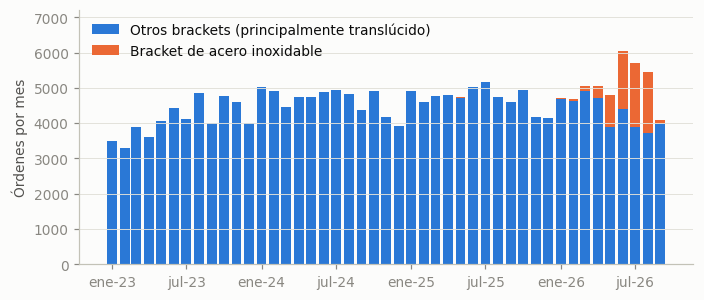

In [7]:
# Figura 1. Órdenes mensuales por tipo de bracket
fig, ax = plt.subplots(figsize=(7.2, 3.0))
x = df["mes"]
ax.bar(x, df["resto"], width=24, color=C["azul"], label="Otros brackets (principalmente translúcido)")
ax.bar(x, df["acero"], width=24, bottom=df["resto"], color=C["naranja"], label="Bracket de acero inoxidable")
ax.set(ylabel="Órdenes por mes", ylim=(0, 7200))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(FMT_MES)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=1)
fig.savefig("figuras/fig1_serie_mensual.png"); plt.show()

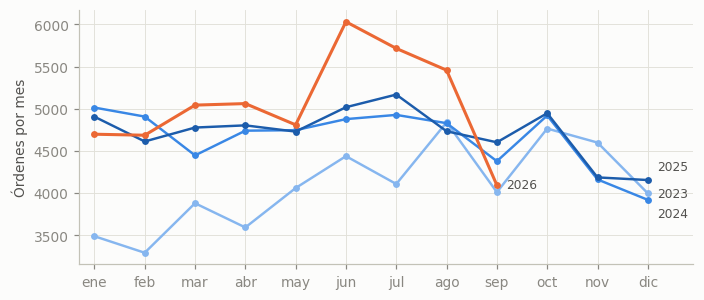

In [8]:
# Figura 2. Perfil anual: un trazo por año, para ver si el patrón por mes se repite
fig, ax = plt.subplots(figsize=(7.2, 3.0))
colores = {2023: C["azul_claro"], 2024: C["azul_medio"], 2025: C["azul_oscuro"], 2026: C["naranja"]}
for anio, g in serie.groupby(serie.index.year):
    ax.plot(g.index.month, g.values, color=colores[anio], lw=2 if anio == 2026 else 1.6, marker="o", ms=3.5)
    ax.annotate(str(anio), xy=(g.index.month[-1], g.values[-1]), xytext=(6, {2025: 9, 2023: 0, 2024: -9}.get(anio, 0)), textcoords="offset points",
                va="center", fontsize=8, color=C["tinta2"])
ax.set(ylabel="Órdenes por mes", xlim=(0.7, 12.9))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(nombres_mes)
fig.savefig("figuras/fig2_perfil_anual.png"); plt.show()

Fuerza de la tendencia: 0.65 | Fuerza de la estacionalidad anual: 0.51
ACF rezago 1: 0.50 | 2: 0.35 | 6: -0.02 | 12: 0.16


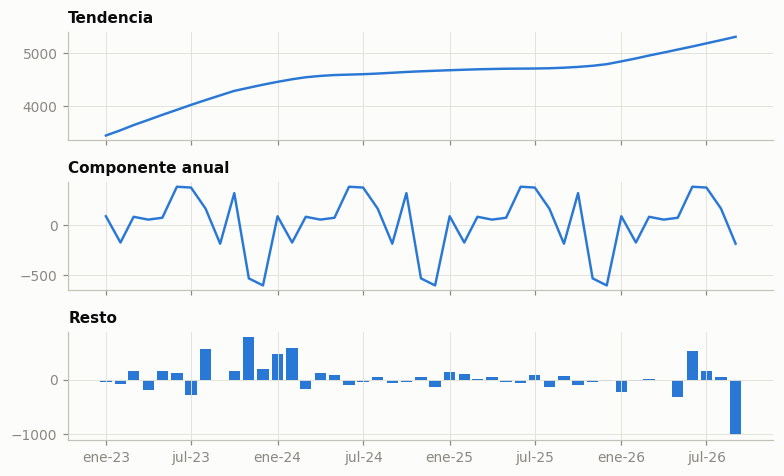

Resto de mayor magnitud: {Timestamp('2026-09-01 00:00:00'): 1021.0, Timestamp('2023-11-01 00:00:00'): 787.0, Timestamp('2024-02-01 00:00:00'): 579.0, Timestamp('2023-08-01 00:00:00'): 565.0}


In [9]:
# Figura 3. Descomposición STL robusta con período 12 (tendencia, componente anual y resto)
# seasonal=99 con seasonal_deg=0: el componente anual es el mismo cada año, equivalente a season(window = "periodic") de fpp3
stl = STL(serie, period=12, seasonal=99, seasonal_deg=0, robust=True).fit()
Ft = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
Fs = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
print("Fuerza de la tendencia: %.2f | Fuerza de la estacionalidad anual: %.2f" % (Ft, Fs))
a = acf(serie, nlags=12)
print("ACF rezago 1: %.2f | 2: %.2f | 6: %.2f | 12: %.2f" % (a[1], a[2], a[6], a[12]))

fig, ax = plt.subplots(3, 1, figsize=(7.2, 4.4), sharex=True)
ax[0].plot(stl.trend, color=C["azul"], lw=1.6); ax[0].set_title("Tendencia")
ax[1].plot(stl.seasonal, color=C["azul"], lw=1.6); ax[1].set_title("Componente anual")
ax[2].bar(stl.resid.index, stl.resid.values, width=24, color=C["azul"]); ax[2].set_title("Resto")
ax[2].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax[2].xaxis.set_major_formatter(FMT_MES)
fig.tight_layout(); fig.savefig("figuras/fig3_stl.png"); plt.show()
print("Resto de mayor magnitud:", stl.resid.abs().nlargest(4).round(0).to_dict())

## 4. Primer modelo: identificación del SARIMA

In [10]:
# Estacionariedad: ADF (H0: raíz unitaria; p bajo = estacionaria) y KPSS (H0: estacionaria; p bajo = no estacionaria)
# Nota: statsmodels acota el p-valor de KPSS al rango [0.01, 0.10].
for etiqueta, x in [("serie original (45 meses)", serie),
                    ("diferencia estacional (1 - B^12), 33 meses", serie.diff(12).dropna()),
                    ("(1 - B)(1 - B^12), 32 meses", serie.diff(12).diff().dropna())]:
    print("%-44s ADF p = %.4f | KPSS p = %.2f" % (etiqueta, adfuller(x, autolag="AIC")[1], kpss(x, nlags="auto")[1]))

serie original (45 meses)                    ADF p = 0.0019 | KPSS p = 0.02
diferencia estacional (1 - B^12), 33 meses   ADF p = 0.0064 | KPSS p = 0.10
(1 - B)(1 - B^12), 32 meses                  ADF p = 0.0000 | KPSS p = 0.10


In [11]:
# Ventana expansiva: la primera usa 24 meses de entrenamiento y pronostica 3 meses; después se agrega un mes por ventana
H, M, INI = 3, 12, 24
datos = pd.DataFrame({"unique_id": "ordenes", "ds": serie.index, "y": serie.values})
N_VENT = len(datos) - INI - H + 1
print("Ventanas:", N_VENT, "| primer entrenamiento: %s a %s | último pronóstico: %s" %
      (serie.index[0].strftime("%Y-%m"), serie.index[INI - 1].strftime("%Y-%m"), serie.index[-1].strftime("%Y-%m")))

def texto_orden(modelo):
    p, q, P, Q, m_, d, D = modelo.model_["arma"]             # convención de statsforecast: (p, q, P, Q, m, d, D)
    return "(%d,%d,%d)(%d,%d,%d)[%d]" % (p, d, q, P, D, Q, m_)

# El orden se vuelve a identificar (AICc) en cada ventana usando SOLO los datos anteriores al origen
ordenes_elegidos = {}
for k in range(INI, len(datos) - H + 1):
    sf_id = StatsForecast(models=[AutoARIMA(season_length=M)], freq="MS")
    sf_id.fit(datos.iloc[:k])
    ordenes_elegidos[serie.index[k - 1]] = texto_orden(sf_id.fitted_[0, 0])
elegidos = pd.Series(ordenes_elegidos)
print("\nOrdenes elegidos por AutoARIMA en las %d ventanas:" % N_VENT)
print(elegidos.value_counts().to_string())

# Orden con los 45 meses (el que se usa para el pronóstico final)
sf_fin_id = StatsForecast(models=[AutoARIMA(season_length=M)], freq="MS")
sf_fin_id.fit(datos)
orden_final = texto_orden(sf_fin_id.fitted_[0, 0])
print("\nOrden con los 45 meses: SARIMA" + orden_final)

Ventanas: 19 | primer entrenamiento: 2023-01 a 2024-12 | último pronóstico: 2026-09



Ordenes elegidos por AutoARIMA en las 19 ventanas:
(1,1,0)(0,1,0)[12]    10
(3,1,0)(0,1,0)[12]     7
(0,1,2)(0,0,0)[12]     1
(3,2,0)(0,1,0)[12]     1

Orden con los 45 meses: SARIMA(1,1,0)(0,1,0)[12]


## 5. Validación de ventana expansiva contra los modelos de referencia

In [12]:
nombres = ["SNAIVE", "AutoETS", "SARIMA"]
modelos = [SeasonalNaive(season_length=M, alias="SNAIVE"),            # repite el mismo mes del año anterior
           AutoETS(season_length=M, alias="AutoETS"),
           AutoARIMA(season_length=M, alias="SARIMA")]
sf = StatsForecast(models=modelos, freq="MS", n_jobs=1)
cv = sf.cross_validation(df=datos, h=H, step_size=1, n_windows=N_VENT, refit=True)
assert cv.cutoff.nunique() == N_VENT and cv.cutoff.min() == serie.index[INI - 1]
for nom in nombres:
    cv[nom] = cv[nom].clip(lower=0)                                    # restricción: los conteos no son negativos
print("Pronósticos evaluados:", len(cv), "(", cv.cutoff.nunique(), "ventanas x", H, "meses )")

Pronósticos evaluados: 57 ( 19 ventanas x 3 meses )


In [13]:
def escala_mase(corte):
    """Error absoluto medio del ingenuo estacional (m = 12) dentro del entrenamiento hasta `corte`."""
    ent = serie[:corte].values
    return np.mean(np.abs(ent[M:] - ent[:-M]))

filas = []
for corte, g in cv.groupby("cutoff"):
    esc = escala_mase(corte)
    for nom in nombres:
        e = g["y"] - g[nom]
        filas.append(dict(corte=corte, modelo=nom, mae=np.mean(np.abs(e)), mase=np.mean(np.abs(e)) / esc))
met = pd.DataFrame(filas)
pv = met.pivot(index="corte", columns="modelo", values="mase")[nombres]

def tabla(sub_cv, sub_met):
    out = pd.DataFrame({
        "MAE": {n: np.mean(np.abs(sub_cv["y"] - sub_cv[n])) for n in nombres},
        "RMSE": {n: np.sqrt(np.mean((sub_cv["y"] - sub_cv[n]) ** 2)) for n in nombres},
        "MASE (prom.)": sub_met.groupby("modelo").mase.mean(),
        "MASE (mediana)": sub_met.groupby("modelo").mase.median()}).loc[nombres]
    return out.round(3)

print("TODAS LAS VENTANAS (n = %d)" % met.corte.nunique())
print(tabla(cv, met).to_string())
print("Ventanas en que SARIMA tiene menor MASE que SNAIVE: %d de %d" % ((pv.SARIMA < pv.SNAIVE).sum(), len(pv)))
print("Ventanas en que AutoETS tiene menor MASE que SNAIVE: %d de %d" % ((pv.AutoETS < pv.SNAIVE).sum(), len(pv)))
print("Prueba de Wilcoxon (SARIMA vs SNAIVE, MASE por ventana): p = %.3f" % wilcoxon(pv.SARIMA, pv.SNAIVE).pvalue)

TODAS LAS VENTANAS (n = 19)
                MAE        RMSE  MASE (prom.)  MASE (mediana)
SNAIVE   248.876999  349.605988         0.594           0.375
AutoETS  343.117004  486.032990         0.828           0.545
SARIMA   279.597992  413.671997         0.623           0.432
Ventanas en que SARIMA tiene menor MASE que SNAIVE: 9 de 19
Ventanas en que AutoETS tiene menor MASE que SNAIVE: 4 de 19
Prueba de Wilcoxon (SARIMA vs SNAIVE, MASE por ventana): p = 0.568


In [14]:
# Antes y durante el lanzamiento del acero: ventanas con origen anterior a marzo de 2026 (pronostican hasta mayo de 2026)
# frente a ventanas con origen en marzo de 2026 o después (pronostican abril a septiembre de 2026)
quiebre = pd.Timestamp("2026-03-01")
post = cv.cutoff >= quiebre
print("ORIGEN ANTERIOR A MARZO DE 2026 (n = %d ventanas)" % cv[~post].cutoff.nunique())
print(tabla(cv[~post], met[met.corte < quiebre]).to_string())
print("\nORIGEN EN MARZO DE 2026 O DESPUÉS (n = %d ventanas)" % cv[post].cutoff.nunique())
print(tabla(cv[post], met[met.corte >= quiebre]).to_string())

# Sesgo por periodo (pronóstico medio contra real medio)
for etiqueta, g in [("origen < mar-2026", cv[~post]), ("origen >= mar-2026", cv[post])]:
    print("Sesgo SARIMA, %-18s pronóstico medio %.0f vs real medio %.0f (%+.0f %%)" %
          (etiqueta + ":", g.SARIMA.mean(), g.y.mean(), 100 * (g.SARIMA.sum() / g.y.sum() - 1)))
    print("Sesgo SNAIVE, %-18s pronóstico medio %.0f vs real medio %.0f (%+.0f %%)" %
          (etiqueta + ":", g.SNAIVE.mean(), g.y.mean(), 100 * (g.SNAIVE.sum() / g.y.sum() - 1)))

ORIGEN ANTERIOR A MARZO DE 2026 (n = 15 ventanas)
                MAE        RMSE  MASE (prom.)  MASE (mediana)
SNAIVE   158.488998  188.848007         0.332           0.365
AutoETS  224.785995  295.710999         0.487           0.511
SARIMA   218.210999  306.720001         0.427           0.326

ORIGEN EN MARZO DE 2026 O DESPUÉS (n = 4 ventanas)
                MAE        RMSE  MASE (prom.)  MASE (mediana)
SNAIVE   587.833008  668.450989         1.574           1.503
AutoETS  786.857971  891.158020         2.107           2.050
SARIMA   509.802002  678.271973         1.360           1.393
Sesgo SARIMA, origen < mar-2026: pronóstico medio 4643 vs real medio 4750 (-2 %)
Sesgo SNAIVE, origen < mar-2026: pronóstico medio 4665 vs real medio 4750 (-2 %)
Sesgo SARIMA, origen >= mar-2026: pronóstico medio 5322 vs real medio 5411 (-2 %)
Sesgo SNAIVE, origen >= mar-2026: pronóstico medio 4908 vs real medio 5411 (-9 %)


In [15]:
# Sensibilidad: ajuste por días hábiles. Se modela el promedio por día hábil (lunes a viernes) y se multiplica de vuelta
# por los días hábiles del mes pronosticado. El análisis principal NO usa este ajuste.
datos_dl = datos.assign(y=datos["y"].values / dl.values)
sf2 = StatsForecast(models=modelos, freq="MS", n_jobs=1)
cv2 = sf2.cross_validation(df=datos_dl, h=H, step_size=1, n_windows=N_VENT, refit=True)
filas2 = []
for corte, g in cv2.groupby("cutoff"):
    esc = escala_mase(corte)
    dlg = dl.reindex(g.ds).values
    for nom in nombres:
        e = serie.reindex(g.ds).values - np.clip(g[nom].values, 0, None) * dlg
        filas2.append(dict(corte=corte, modelo=nom, mase=np.mean(np.abs(e)) / esc, mae=np.mean(np.abs(e))))
met2 = pd.DataFrame(filas2)
pv2 = met2.pivot(index="corte", columns="modelo", values="mase")[nombres]
print("AJUSTE POR DÍAS HÁBILES, todas las ventanas (MASE prom. | MAE):")
print(pd.DataFrame({"MASE": met2.groupby("modelo").mase.mean(), "MAE": met2.groupby("modelo").mae.mean()}).loc[nombres].round(3).to_string())
print("SARIMA menor que SNAIVE en %d de %d ventanas | Wilcoxon p = %.3f" % ((pv2.SARIMA < pv2.SNAIVE).sum(), len(pv2), wilcoxon(pv2.SARIMA, pv2.SNAIVE).pvalue))
print("Origen < mar-2026:", pv2[pv2.index < quiebre].mean().round(3).to_dict())
print("Origen >= mar-2026:", pv2[pv2.index >= quiebre].mean().round(3).to_dict())

AJUSTE POR DÍAS HÁBILES, todas las ventanas (MASE prom. | MAE):
          MASE      MAE
modelo                 
SNAIVE   0.514  215.369
AutoETS  0.641  287.393
SARIMA   0.564  258.016
SARIMA menor que SNAIVE en 7 de 19 ventanas | Wilcoxon p = 0.210
Origen < mar-2026: {'SNAIVE': 0.249, 'AutoETS': 0.551, 'SARIMA': 0.436}
Origen >= mar-2026: {'SNAIVE': 1.508, 'AutoETS': 0.979, 'SARIMA': 1.044}


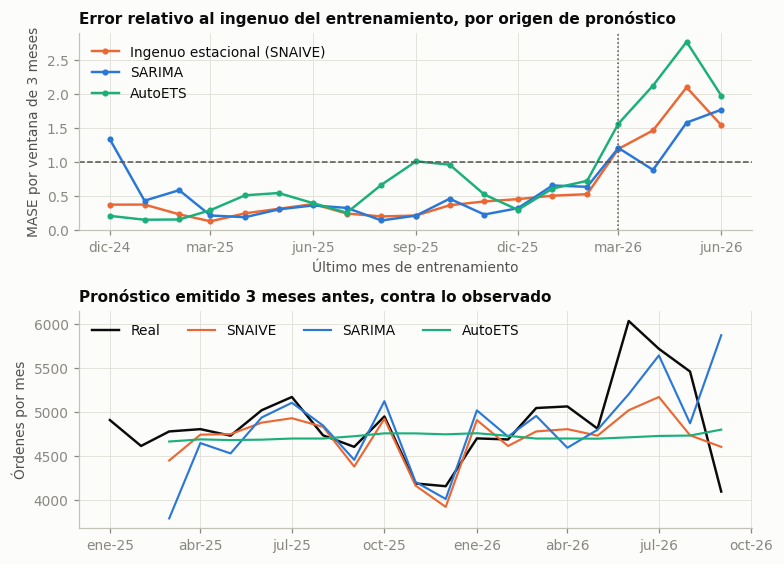

In [16]:
# Figura 4. MASE por ventana y pronóstico a 3 meses vista contra lo observado
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 5.2), gridspec_kw={"height_ratios": [1, 1.1]})
a1.plot(pv.index, pv.SNAIVE, color=C["naranja"], lw=1.6, marker="o", ms=3, label="Ingenuo estacional (SNAIVE)")
a1.plot(pv.index, pv.SARIMA, color=C["azul"], lw=1.6, marker="o", ms=3, label="SARIMA")
a1.plot(pv.index, pv.AutoETS, color=C["aqua"], lw=1.6, marker="o", ms=3, label="AutoETS")
a1.axhline(1, color=C["tinta2"], lw=1, ls="--")
a1.axvline(quiebre, color=C["tinta2"], lw=1, ls=":")
a1.set(ylabel="MASE por ventana de 3 meses", title="Error relativo al ingenuo del entrenamiento, por origen de pronóstico",
       xlabel="Último mes de entrenamiento")
a1.legend(loc="upper left", ncol=1)
a1.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); a1.xaxis.set_major_formatter(FMT_MES)

h3 = cv[cv.groupby("cutoff").cumcount() == H - 1].set_index("ds")        # el tercer mes de cada ventana
a2.plot(serie["2025-01":].index, serie["2025-01":].values, color=C["tinta"], lw=1.6, label="Real")
a2.plot(h3.index, h3.SNAIVE, color=C["naranja"], lw=1.4, label="SNAIVE")
a2.plot(h3.index, h3.SARIMA, color=C["azul"], lw=1.4, label="SARIMA")
a2.plot(h3.index, h3.AutoETS, color=C["aqua"], lw=1.4, label="AutoETS")
a2.set(ylabel="Órdenes por mes", title="Pronóstico emitido 3 meses antes, contra lo observado")
a2.legend(loc="upper left", ncol=4)
a2.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); a2.xaxis.set_major_formatter(FMT_MES)
fig.tight_layout(); fig.savefig("figuras/fig4_validacion.png"); plt.show()

## 6. Diagnóstico de residuos y pronóstico a 3 meses

Residuos de SARIMA(1,1,0)(0,1,0)[12] (n = 32)
Ljung-Box (gl ajustados por 1 parámetros ARMA):
    lb_stat  lb_pvalue
6     2.910      0.714
12    9.177      0.606
Residuos: media -79.0 | desviación 396.8 | asimetría -0.70


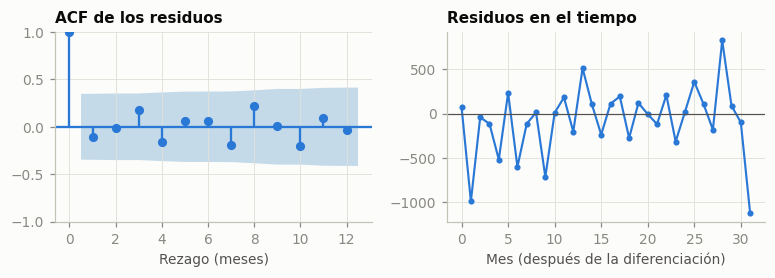

In [17]:
sf_final = StatsForecast(models=[AutoARIMA(season_length=M, alias="SARIMA")], freq="MS")
pron = sf_final.forecast(df=datos, h=H, level=[80, 95], fitted=True)
ajuste = sf_final.forecast_fitted_values()
n_perd = 13                                                                         # d + D*12 = 13 meses perdidos por la diferenciación
res = (ajuste["y"] - ajuste["SARIMA"]).iloc[n_perd:]
p_, q_, P_, Q_ = [int(v) for v in sf_fin_id.fitted_[0, 0].model_["arma"][:4]]
lb = acorr_ljungbox(res, lags=[6, 12], model_df=p_ + q_ + P_ + Q_)
print("Residuos de SARIMA" + orden_final + " (n = %d)" % len(res))
print("Ljung-Box (gl ajustados por %d parámetros ARMA):" % (p_ + q_ + P_ + Q_))
print(lb.round(3).to_string())
print("Residuos: media %.1f | desviación %.1f | asimetría %.2f" % (res.mean(), res.std(), res.skew()))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 2.6))
plot_acf(res, lags=12, ax=a1, color=C["azul"], vlines_kwargs=dict(colors=C["azul"]), alpha=0.05, title="ACF de los residuos")
a1.set(xlabel="Rezago (meses)")
a2.plot(res.values, color=C["azul"], lw=1.4, marker="o", ms=3)
a2.axhline(0, color=C["tinta2"], lw=0.8); a2.set(title="Residuos en el tiempo", xlabel="Mes (después de la diferenciación)")
fig.tight_layout(); fig.savefig("figuras/fig5_residuos.png"); plt.show()

     ds  SARIMA  SARIMA-lo-80  SARIMA-hi-80  SARIMA-lo-95  SARIMA-hi-95  SNAIVE  AutoETS
2026-10  5172.0        4653.0        5691.0        4379.0        5966.0  4948.0   4846.0
2026-11  3976.0        3416.0        4536.0        3120.0        4832.0  4187.0   4847.0
2026-12  4204.0        3519.0        4888.0        3157.0        5251.0  4156.0   4847.0
Mismo trimestre de 2025 (oct-dic):  [4948, 4187, 4156] | total 13291
Total pronosticado SARIMA oct-dic 2026: 13352 | SNAIVE: 13291 | AutoETS: 14540
Octubre 2026 observado hasta el día 25: 3036 órdenes (25 de 31 días)


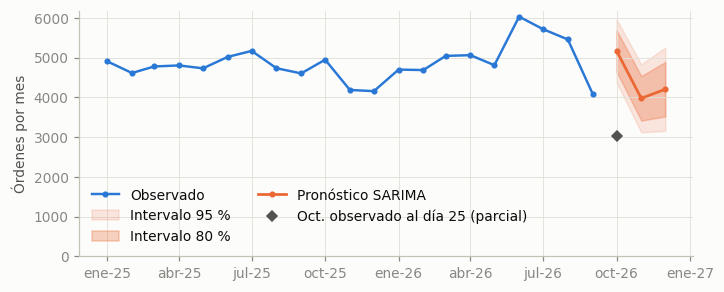

In [18]:
# Pronóstico de octubre a diciembre de 2026, con intervalos del 80 % y 95 %, junto a las referencias
snaive_fin = StatsForecast(models=[SeasonalNaive(season_length=M, alias="SNAIVE")], freq="MS").forecast(df=datos, h=H)
ets_fin = StatsForecast(models=[AutoETS(season_length=M, alias="AutoETS")], freq="MS").forecast(df=datos, h=H)
tab = pron[["ds", "SARIMA", "SARIMA-lo-80", "SARIMA-hi-80", "SARIMA-lo-95", "SARIMA-hi-95"]].copy()
tab["SNAIVE"] = snaive_fin["SNAIVE"].values
tab["AutoETS"] = ets_fin["AutoETS"].values
print(tab.round(0).assign(ds=lambda x: x.ds.dt.strftime("%Y-%m")).to_string(index=False))
print("Mismo trimestre de 2025 (oct-dic): ", serie["2025-10":"2025-12"].astype(int).tolist(), "| total", int(serie["2025-10":"2025-12"].sum()))
print("Total pronosticado SARIMA oct-dic 2026: %.0f | SNAIVE: %.0f | AutoETS: %.0f" % (tab.SARIMA.sum(), tab.SNAIVE.sum(), tab.AutoETS.sum()))
print("Octubre 2026 observado hasta el día 25: %d órdenes (%d de 31 días)" % (OCT_PARCIAL["ordenes"], OCT_PARCIAL["dias_observados"]))

fig, ax = plt.subplots(figsize=(7.2, 2.9))
hist = serie["2025-01":]
ax.plot(hist.index, hist.values, color=C["azul"], lw=1.6, marker="o", ms=3, label="Observado")
ax.fill_between(pron.ds, pron["SARIMA-lo-95"].clip(lower=0), pron["SARIMA-hi-95"], color=C["naranja"], alpha=0.15, label="Intervalo 95 %")
ax.fill_between(pron.ds, pron["SARIMA-lo-80"].clip(lower=0), pron["SARIMA-hi-80"], color=C["naranja"], alpha=0.30, label="Intervalo 80 %")
ax.plot(pron.ds, pron.SARIMA.clip(lower=0), color=C["naranja"], lw=1.8, marker="o", ms=3, label="Pronóstico SARIMA")
ax.plot([pd.Timestamp("2026-10-01")], [OCT_PARCIAL["ordenes"]], marker="D", ms=5, color=C["tinta2"], ls="none", label="Oct. observado al día 25 (parcial)")
ax.set(ylabel="Órdenes por mes", ylim=(0, None)); ax.legend(loc="lower left", ncol=2)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(FMT_MES)
fig.savefig("figuras/fig6_pronostico.png"); plt.show()

## 7. Conclusiones del primer modelo

- **El SARIMA(1,1,0)(0,1,0)[12] no supera de forma consistente al ingenuo estacional.** Con 19 ventanas de 3 meses, el MASE promedio es 0.62 para el SARIMA contra 0.59 para SNAIVE; el SARIMA gana en 9 de 19 ventanas y la prueba de Wilcoxon no encuentra diferencia (p = 0.57). AutoETS queda peor (0.83): con solo tres años completos elige un modelo sin componente estacional.
- **Antes del auge del acero, repetir el mismo mes del año anterior es lo mejor** (MASE 0.33 contra 0.43 del SARIMA en 15 ventanas), porque el patrón anual de 2024 y 2025 es casi el mismo. Con origen en marzo de 2026 o después (4 ventanas), los tres fallan (SNAIVE 1.57, SARIMA 1.36, AutoETS 2.11), y el SARIMA es el menos malo; con cuatro ventanas es una pista, no una conclusión.
- **El orden del SARIMA es inestable:** AutoARIMA eligió cuatro órdenes distintos a lo largo de las 19 ventanas. Es lo esperable con 24 a 42 meses y una diferencia estacional que consume 12.
- **Los residuos son compatibles con ruido blanco** (Ljung-Box p = 0.71 y 0.61), pero con solo 32 residuos la prueba detecta poco.
- **El ajuste por días hábiles mejora a los tres modelos** (MASE: SNAIVE 0.51, SARIMA 0.56, AutoETS 0.64) pero no cambia cuál es el mejor en el conjunto. Con origen desde marzo de 2026 sí cambia el orden: AutoETS 0.98, SARIMA 1.04 y SNAIVE 1.51.
- **Pronóstico de octubre a diciembre de 2026:** el SARIMA da 5,172, 3,976 y 4,204 órdenes (13,352 en total), casi igual al ingenuo (13,291). **El valor de octubre no es confiable:** al día 25 ya hay 3,036 órdenes, y si los seis días restantes se parecen a la última semana el mes cerraría cerca de 4,000, por debajo del intervalo del 80 % (4,653 a 5,691). El SARIMA arrastra el nivel alto de junio a agosto.
- **Siguiente paso (Avance 2):** un segundo método que incorpore el estado del producto de acero y los días hábiles, evaluado con las mismas ventanas, y avanzar hacia el pronóstico diario con el que se ve mejor la estacionalidad semanal.